# Rest days and Elo

Two additions to the pre-game features:

- **Rest:** days since the team's previous game, capped at 4, and a back-to-back flag.
- **Elo** (`nba_predictor.elo`), written from scratch. Ratings start at 1500 and move after each game by K × (result − expected), scaled up for bigger wins. There's no home bonus on neutral courts or in the bubble, and ratings are pulled toward 1500 between seasons.

Elo's three settings were tuned by log loss on **training seasons only** (2015-16 to 2019-20, with 2014-15 as burn-in). Validation stays clean for comparing models on day 6. Everything below uses the same seasons, except the back-to-back table, which also includes 2014-15 (rest doesn't depend on Elo's burn-in).

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("NBA_DATA_DIR", "../data")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from nba_predictor.elo import log_loss
from nba_predictor.evaluate import wilson

tuned = json.loads(Path("../reports/elo.json").read_text())
feats = pd.read_parquet(Path(os.environ["NBA_DATA_DIR"]) / "processed" / "features.parquet")
train = feats[(feats["season"] <= "2019-20") & (feats["season"] != "2014-15")]
pd.DataFrame(tuned["top_5"])

,k,home,carry,mov,log_loss
0,15,60,0.80,True,0.61234
1,15,60,0.65,True,0.61260
2,20,60,0.65,True,0.61288
3,15,80,0.80,True,0.61295
4,20,60,0.80,True,0.61296


- **Best:** K = 15, home bonus 60 points, carry-over 0.8, margin of victory on. None is at the edge of the grid.
- **The top 5 are within 0.0007 of each other,** so the exact values hardly matter.
- **Sanity check:** a 60-point bonus means 58.5% for two equal teams. Home teams won 58.4% of games in 2014-15 to 2018-19.

In [2]:
y = train["home_win"]
pd.DataFrame(
    {
        "log loss": {
            "always the home win rate": log_loss(y, np.full(len(y), y.mean())),
            "Elo": log_loss(y, train["elo_prob"]),
        },
        "AUC": {"always the home win rate": 0.5, "Elo": roc_auc_score(y, train["elo_prob"])},
    }
).round(4)

,log loss,AUC
always the home win rate,0.6803,0.5000
Elo,0.6123,0.7069


In [3]:
first = train[["home_games_played", "away_games_played"]].min(axis=1)
bucket = pd.cut(first, [-1, 0, 9, 100], labels=["opening game", "games 1-9", "10+"])
rows = []
for name, g in train.groupby(bucket, observed=True):
    rows.append(
        {
            "when": name,
            "games": len(g),
            "Elo AUC": roc_auc_score(g["home_win"], g["elo_prob"]),
            "margin so far AUC": roc_auc_score(g["home_win"], g["diff_margin_avg"]),
        }
    )
pd.DataFrame(rows).set_index("when").round(3)

,games,Elo AUC,margin so far AUC
when,,,
opening game,81,0.688,0.501
games 1-9,696,0.674,0.632
10+,5202,0.711,0.702


**Elo's carry-over fixes the early season.** In teams' first 9 games, Elo's AUC is 0.674 against 0.632 for the margin so far. On opening night it's 0.688, where the season-to-date features have nothing yet (0.50). From game 10 on, the two are close (0.711 vs 0.702).

,predicted,won
elo_prob,,
"(0.076, 0.325]",0.255,0.246
"(0.325, 0.409]",0.371,0.388
"(0.409, 0.475]",0.443,0.450
"(0.475, 0.531]",0.504,0.538
"(0.531, 0.582]",0.558,0.545
"(0.582, 0.631]",0.607,0.633
"(0.631, 0.681]",0.656,0.679
"(0.681, 0.741]",0.710,0.709
"(0.741, 0.802]",0.771,0.749


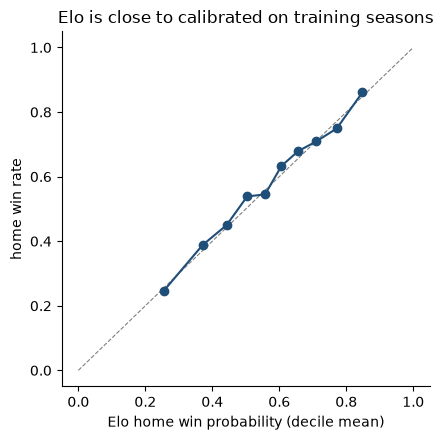

In [4]:
q = pd.qcut(train["elo_prob"], 10)
cal = train.groupby(q, observed=True).agg(predicted=("elo_prob", "mean"), won=("home_win", "mean"))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], color="grey", lw=0.8, ls="--")
ax.plot(cal["predicted"], cal["won"], "o-", color="#1f4e79")
ax.set_xlabel("Elo home win probability (decile mean)")
ax.set_ylabel("home win rate")
ax.set_title("Elo is close to calibrated on training seasons")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/elo_calibration.png", dpi=150)
cal.round(3)

## Back-to-backs

In [5]:
all_train = feats[feats["season"] <= "2019-20"]
cases = {
    "both rested": (all_train["home_b2b"] == 0) & (all_train["away_b2b"] == 0),
    "home on a back-to-back": (all_train["home_b2b"] == 1) & (all_train["away_b2b"] == 0),
    "away on a back-to-back": (all_train["home_b2b"] == 0) & (all_train["away_b2b"] == 1),
    "both": (all_train["home_b2b"] == 1) & (all_train["away_b2b"] == 1),
}
rows = []
for name, m in cases.items():
    g = all_train[m]
    low, high = wilson(int(g["home_win"].sum()), len(g))
    rows.append(
        {
            "case": name,
            "games": len(g),
            "home won": g["home_win"].mean(),
            "95%": f"{low:.3f} to {high:.3f}",
            "Elo predicted": g["elo_prob"].mean(),
        }
    )
pd.DataFrame(rows).set_index("case").round(3)

,games,home won,95%,Elo predicted
case,,,,
both rested,4832,0.571,0.557 to 0.585,0.573
home on a back-to-back,550,0.533,0.491 to 0.574,0.572
away on a back-to-back,1453,0.617,0.592 to 0.642,0.574
both,374,0.602,0.551 to 0.650,0.576


## Findings

1. **Elo beats every day 4 feature on its own:** log loss 0.612 against 0.680 for always predicting the home win rate, and AUC 0.707 against 0.69 for the margin so far. It's the baseline to beat on day 6.
2. **It's close to calibrated,** with every decile within 3.5 points of the observed rate. Day 3's warning still applies: validation has a weaker home edge (54.4%) than the seasons the 60-point bonus was tuned on.
3. **Back-to-backs are information Elo misses.** When only the away team played the night before, home teams won 61.7% (59.2 to 64.2) where Elo expected 57.4%. When only the home team did, they won 53.3% against 57.2% expected. That's about 4 points either way, which the models on day 6 can pick up from `b2b` and `rest_days`.
4. **Away teams are on back-to-backs 2.6 times as often** (1,453 games against 550 for home teams). That comes from the schedule: road trips string games together.